# MASSPEC (1970), step by step

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/BioGeek/MASSPEC/blob/main/notebooks/masspec_1970.ipynb)

Margaret O. Dayhoff and Richard V. Eck, "MASSPEC: A computer program for
complete sequence analysis of large proteins from mass spectrometry data of a
single sample", *Computers in Biology and Medicine* 1, 5-28 (1970),
[doi:10.1016/0010-4825(70)90013-2][doi].

[doi]: https://doi.org/10.1016/0010-4825(70)90013-2

Their proposal: break a protein near-randomly (partial acid hydrolysis), make
the fragments volatile, and measure the whole mixture in **one**
high-resolution mass spectrum. An exact mass fixes a fragment's elemental
formula but not its sequence, nor even its amino acid composition (Ala-Val and
Gly-Leu weigh the same). The sequence is recovered as the one set of
overlapping fragments that is mutually consistent among the thousands of
spurious candidates the same masses also allow.

They demonstrated it on simulated, ideal data for bovine insulin. This notebook
redoes that experiment with the reimplementation in this repository
(`src/masspec`), one program at a time, and regenerates each figure of the
paper next to the values the paper prints. **The code is a reimplementation
from the paper's description, not the original program, which appears to be
lost.**

The paper's one-letter code is used throughout: **J** is leucine or isoleucine
(they weigh the same, so the method cannot tell them apart) and **O** is
tyrosine.

In [1]:
# On Colab, or anywhere else the package is not installed yet, install it
# from GitHub. In a clone, `uv sync --group notebook` has already done so.
import importlib
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("masspec") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "--quiet",
         "masspec @ git+https://github.com/BioGeek/MASSPEC"],
        check=True,
    )
    importlib.invalidate_caches()

In [2]:
import random
from itertools import combinations_with_replacement

import matplotlib.pyplot as plt

from masspec.fragments import add_noise, fragen, ideal_masses
from masspec.masses import _FREE_1970, H2O, H2O_1970, MASSES, MASSES_1970
from masspec.mspec import (
    Observed,
    canon,
    cq,
    masfrg,
    overlap_step,
    prune,
    run,
)


def peptide_mass(residues):
    # peptide mass: residues plus one water
    return sum(MASSES_1970[residue] for residue in residues) + H2O_1970


def composition(residues):
    # composition, letters in alphabetical order
    return "".join(sorted(residues))


def difference(first, second):
    # first - second, rounded to the five decimals the paper prints. Adding
    # 0.0 turns a negative zero (a leftover such as -1e-12) into a plain 0.
    return round(first - second, 5) + 0.0


# insulin A chain, bovine (21 residues)
INSULIN_A = "GJVEQCCASVCSJOQJENOCN"
# insulin B chain, bovine (30 residues)
INSULIN_B = "FVNQHJCGSHJVEAJOJVCGERGFFOTPKA"

## Fig. 2: the masses

The paper lists the monoisotopic masses of the free amino acids; a peptide
weighs their sum minus one water per peptide bond, which is the same as the sum
of RESIDUE masses plus one water. Below, the paper's values beside present-day
ones (free amino acid = residue + water).

One entry is wrong in the paper: tryptophan is printed as 188.09489, one
oxygen short. That is C11H12N2O, as if the residue had been given H2 rather
than H2O; free tryptophan (C11H12N2O2) weighs 204.0899. The program evidently
ran on the printed value, because the counts in Figs. 6-8 are only reproduced
with it (see below). Insulin has no tryptophan, so the slip never showed.

In [3]:
# Fig. 2's rows, in its order. It also lists Ile (I) and Leu (L), with the
# same mass as J; the program itself only uses J.
ACIDS = {
    "A": "Ala", "C": "Cys", "E": "Glu", "F": "Phe", "G": "Gly", "D": "Asp",
    "H": "His", "J": "Lux (Ile or Leu)", "K": "Lys", "M": "Met",
    "N": "Asn", "O": "Tyr", "P": "Pro", "Q": "Gln", "R": "Arg", "S": "Ser",
    "T": "Thr", "V": "Val", "W": "Trp",
}
modern = {"J": MASSES["L"], "O": MASSES["Y"], **MASSES}
print(
    f"{'Acid':<18}{'Code':<6}{'Mass':>11}{'Present-Day':>13}"
    f"{'Difference':>12}"
)
for code, acid in ACIDS.items():
    now = modern[code] + H2O  # free amino acid = residue + water
    printed = _FREE_1970[code]
    gap = difference(printed, now)
    print(f"{acid:<18}{code:<6}{printed:11.5f}{now:13.5f}{gap:12.5f}")
water_gap = difference(H2O_1970, H2O)
print(f"{'H2O':<24}{H2O_1970:11.5f}{H2O:13.5f}{water_gap:12.5f}")

Acid              Code         Mass  Present-Day  Difference
Ala               A        89.04763     89.04768    -0.00005
Cys               C       121.01970    121.01975    -0.00005
Glu               E       147.05309    147.05316    -0.00007
Phe               F       165.07891    165.07898    -0.00007
Gly               G        75.03199     75.03203    -0.00004
Asp               D       133.03745    133.03751    -0.00006
His               H       155.06941    155.06948    -0.00007
Lux (Ile or Leu)  J       131.09455    131.09463    -0.00008
Lys               K       146.10544    146.10553    -0.00009
Met               M       149.05098    149.05105    -0.00007
Asn               N       132.05343    132.05349    -0.00006
Tyr               O       181.07382    181.07389    -0.00007
Pro               P       115.06327    115.06333    -0.00006
Gln               Q       146.06907    146.06914    -0.00007
Arg               R       174.11158    174.11168    -0.00010
Ser               S     

## Fig. 1: FRAGEN, fragmenting the protein

FRAGEN simulates a random hydrolysis by listing every fragment of the chain.
The masses will only say what a fragment is MADE of, so the paper prints the
amino acid composition of each, in alphabetical order. Fig. 1 shows the 24
fragments seven residues long from the B chain (the paper writes L for Leu
here, J elsewhere).

In [4]:
def as_printed(residues):
    # a composition as Figs. 1, 3 and 4 print it: L for J, letters spaced
    return " ".join(residues.replace("J", "L"))


print("Structure of Initial Polymer, Bovine Insulin\n")
print("A chain - " + " ".join(INSULIN_A))
print("B chain - " + " ".join(INSULIN_B))
print("\nFragments from B Chain\n")
print(f"{'Fragments of Length 7':>21}   Amino Acid Composition")
seven = [INSULIN_B[start:start + 7] for start in range(len(INSULIN_B) - 6)]
for number, fragment in enumerate(seven, 1):
    print(f"{number:21}   {as_printed(composition(fragment))}")

Structure of Initial Polymer, Bovine Insulin

A chain - G J V E Q C C A S V C S J O Q J E N O C N
B chain - F V N Q H J C G S H J V E A J O J V C G E R G F F O T P K A

Fragments from B Chain

Fragments of Length 7   Amino Acid Composition
                    1   C F H L N Q V
                    2   C G H L N Q V
                    3   C G H L N Q S
                    4   C G H H L Q S
                    5   C G H H L L S
                    6   C G H L L S V
                    7   C E G H L S V
                    8   A E G H L S V
                    9   A E H L L S V
                   10   A E H L L O V
                   11   A E L L L O V
                   12   A E L L O V V
                   13   A C E L L O V
                   14   A C G L L O V
                   15   C E G L L O V
                   16   C E G L O R V
                   17   C E G G L R V
                   18   C E F G G R V
                   19   C E F F G G R
                   20   E F F G G O R


## Figs. 3 and 4: MASFRG, the masses of the fragments

MASFRG computes each fragment's mass. Fig. 3 lists the B chain's dipeptides,
Fig. 4 its octapeptides; the paper's values are copied below.

In [5]:
paper_fig3 = {
    "AE": 218.09016, "AK": 217.14251, "AJ": 202.13162, "CG": 178.04113,
    "CJ": 234.10369, "CV": 220.08805, "EG": 204.07452, "ER": 303.15411,
    "EV": 246.12144, "FF": 312.14725, "FG": 222.10034, "FO": 328.14217,
    "FV": 264.14726, "GR": 231.13301, "GS": 162.06397, "HJ": 268.15340,
    "HQ": 283.12791, "HS": 242.10139, "KP": 243.15815, "JO": 294.15781,
    "JV": 230.16290, "NQ": 260.11193, "NV": 231.12178, "OT": 282.12144,
    "PT": 216.11089,
}


def paper_order(residues):
    # Fig. 3 sorts its rows as printed, with L for J: AE, AK, AL, CG...
    return residues.replace("J", "L")


dipeptides = sorted(
    {
        composition(INSULIN_B[start:start + 2])
        for start in range(len(INSULIN_B) - 1)
    },
    key=paper_order,
)
print("Peptides Two Amino Acids Long\n")
print(
    f"{'':3}{'Mass':>12}{'Paper':>12}{'Difference':>12}"
    "   Amino Acid Composition of Peptide"
)
for number, dipeptide in enumerate(dipeptides, 1):
    here = peptide_mass(dipeptide)
    printed = paper_fig3[dipeptide]
    gap = difference(here, printed)
    print(
        f"{number:3}{here:12.5f}{printed:12.5f}{gap:12.5f}"
        f"   {as_printed(dipeptide)}"
    )

Peptides Two Amino Acids Long

           Mass       Paper  Difference   Amino Acid Composition of Peptide
  1   218.09016   218.09016     0.00000   A E
  2   217.14251   217.14251     0.00000   A K
  3   202.13162   202.13162     0.00000   A L
  4   178.04113   178.04113     0.00000   C G
  5   234.10369   234.10369     0.00000   C L
  6   220.08805   220.08805     0.00000   C V
  7   204.07452   204.07452     0.00000   E G
  8   303.15411   303.15411     0.00000   E R
  9   246.12144   246.12144     0.00000   E V
 10   312.14726   312.14725     0.00001   F F
 11   222.10034   222.10034     0.00000   F G
 12   328.14217   328.14217     0.00000   F O
 13   264.14726   264.14726     0.00000   F V
 14   231.13301   231.13301     0.00000   G R
 15   162.06397   162.06397     0.00000   G S
 16   268.15340   268.15340     0.00000   H L
 17   283.12792   283.12791     0.00001   H Q
 18   242.10139   242.10139     0.00000   H S
 19   243.15815   243.15815     0.00000   K P
 20   294.15781   2

In [6]:
paper_fig4 = [
    916.42204, 856.38567, 894.37617, 893.41729, 864.42713, 856.41081,
    814.36389, 824.43874, 930.48057, 956.53258, 918.54208, 908.46723,
    866.42031, 866.42031, 951.48426, 895.42170, 879.42679, 913.41115,
    977.40606, 975.44454, 1015.47582, 1014.52817, 929.46422,
]
eight = [INSULIN_B[start:start + 8] for start in range(len(INSULIN_B) - 7)]
print("Peptides Eight Amino Acids Long\n")
print(
    f"{'':3}{'Mass':>12}{'Paper':>12}{'Difference':>12}"
    "   Amino Acid Composition of Peptide"
)
for number, (fragment, printed) in enumerate(zip(eight, paper_fig4), 1):
    here = peptide_mass(fragment)
    gap = difference(here, printed)
    print(
        f"{number:3}{here:12.5f}{printed:12.5f}{gap:12.5f}"
        f"   {as_printed(composition(fragment))}"
    )

Peptides Eight Amino Acids Long

           Mass       Paper  Difference   Amino Acid Composition of Peptide
  1   916.42205   916.42204     0.00001   C F G H L N Q V
  2   856.38568   856.38567     0.00001   C G H L N Q S V
  3   894.37618   894.37617     0.00001   C G H H L N Q S
  4   893.41730   893.41729     0.00001   C G H H L L Q S
  5   864.42714   864.42713     0.00001   C G H H L L S V
  6   856.41082   856.41081     0.00001   C E G H L L S V
  7   814.36390   814.36389     0.00001   A C E G H L S V
  8   824.43875   824.43874     0.00001   A E G H L L S V
  9   930.48058   930.48057     0.00001   A E H L L O S V
 10   956.53259   956.53258     0.00001   A E H L L L O V
 11   918.54209   918.54208     0.00001   A E L L L O V V
 12   908.46724   908.46723     0.00001   A C E L L O V V
 13   866.42032   866.42031     0.00001   A C E G L L O V
 14   866.42032   866.42031     0.00001   A C E G L L O V
 15   951.48427   951.48426     0.00001   C E G L L O R V
 16   895.42171   895

Every mass agrees with the paper to one unit in the fifth decimal: 22 of the
25 dipeptides exactly (FF, HQ and NQ are one unit lower in the paper), and
every octapeptide one unit lower in the paper.
Rounding rules alone cannot explain that: every mass in Fig. 2 has five
decimals, so these sums have no sixth digit to round or truncate. The original
program evidently carried more digits than it printed. Fig. 2 itself is
computed from elemental formulas with C = 12, H = 1.00782, N = 14.00307, O =
15.99491 and S = 31.97207 (all 18 values come out exactly), and the dipeptides
of Fig. 3 and the tetrapeptides of Fig. 5 all match if the water it subtracts
is 18.010565 rather than the printed 18.01056; the octapeptides fit no single
value. The rest is presumably the floating-point arithmetic of a 1970 machine,
which cannot be recovered from the printed numbers. The table also shows why
the method is hard: rows 13 and 14 are the same composition, and many different
peptides share a mass.

## Fig. 5: PEPMS, the table of all peptide masses

To go back from a mass to what could have made it, the program needs every
composition sorted by mass. PEPMS tabulates them (only up to four residues:
longer ones are generated later, from overlaps). Fig. 5 shows the stretch from
506.24 to 507.27. Each line is a group of compositions with identical formulas;
the step column is the gap to the previous mass. Unlike Figs. 1 and 4, which
are alphabetical, Fig. 5 writes each composition lightest residue first: VNQF
is V (99) < N (114) < Q (128) < F (147). So does this table.

In [7]:
def lightest_first(residue):
    # Fig. 5's order within a composition: by residue mass, then letter.
    return (MASSES_1970[residue], residue)


table = {}
for length in range(1, 5):
    for residues in combinations_with_replacement(sorted(MASSES_1970), length):
        table.setdefault(round(peptide_mass(residues), 5), []).append(
            "".join(sorted(residues, key=lightest_first))
        )
window = sorted(value for value in table if 506.24 <= value <= 507.27)
print(
    f"{'Mass':>11}   {'Peptide Composition':<22}"
    "Increase in Mass from Preceding Entry"
)
previous = None
for group_mass in window:
    first, *others = table[group_mass]
    step = f"{group_mass - previous:.5f}" if previous else ""
    print(f"{group_mass:11.5f}   {first:<22}{step:>9}")
    for other in others:
        print(f"{'':11}   {other}")
    previous = group_mass
anfr_tjhh = difference(peptide_mass("ANFR"), peptide_mass("TJHH"))
jnnf_vnqf = difference(peptide_mass("JNNF"), peptide_mass("VNQF"))
print(f"\nANFR - TJHH = {anfr_tjhh:.5f}    JNNF - VNQF = {jnnf_vnqf:.5f}")

       Mass   Peptide Composition   Increase in Mass from Preceding Entry
  506.24864   JNNF                           
              VNQF
  506.25199   CKKE                    0.00335
              TQKM
  506.25268   PPFF                    0.00069
  506.25603   PJMF                    0.00335
  506.25938   JJMM                    0.00335
  506.25987   ANFR                    0.00049
              GQFR
              TJHH
  506.26322   TCKR                    0.00335
  506.27378   JJDF                    0.01056
              VJEF
  506.28501   VNKF                    0.01123
  506.28836   TKKM                    0.00335
  506.29624   GKFR                    0.00788
  506.31015   VJJO                    0.01391
  507.16327   CQEE                    0.85312
              DDQM
              NDEM
  507.17450   CDDR                    0.01123
  507.17854   TCDW                    0.00404
              SCEW
  507.19629   PNDO                    0.01775
  507.19716   CCJW                    

The groups are the paper's, entry for entry: VNQF with JNNF at 506.24863, TQKM
with CKKE, then PPFF, PJMF and JJMM, and ANFR, GQFR and TJHH together at
506.25986, the paper's own example of a degeneracy (identical elemental
formulas). Within a group the paper's order follows no rule we could find
(probably the order its program generated them); here it is alphabetical. The
masses here are one unit higher in the fifth decimal, for the
reason given under Fig. 4. At a resolution of 0.02 a.m.u. many of these
neighbouring groups also blur together.

## The input: one spectrum of ideal masses

The insulin problem: every fragment of both chains up to nine residues long,
each mass observed once, exactly, and nothing above 1000 a.m.u.

In [8]:
masses = ideal_masses(
    [INSULIN_A, INSULIN_B],
    max_len=9,
    mass_limit=1000.0,
    table=MASSES_1970,
    water=H2O_1970,
)
print(
    len(masses), "distinct masses, from", round(masses[0], 3),
    "to", round(masses[-1], 3),
)
observed = Observed(masses, tol_da=0.02)

302 distinct masses, from 75.032 to 995.463


## Fig. 6: MASFRG, from masses back to compositions

Every composition up to four residues whose mass lies within ±0.02 of an
observed mass. "There are actually only 45 true fragments 3 long. However,
their masses correspond to any of 197 amino acid compositions."

In [9]:
compositions = masfrg(observed, MASSES_1970, H2O_1970, max_len=4)
true_compositions = {
    length: {
        tuple(sorted(fragment))
        for fragment in fragen([INSULIN_A, INSULIN_B], 4)
        if len(fragment) == length
    }
    for length in range(1, 5)
}
print("Insulin of Beef 'A' and 'B'   Limits -.02 to +.02 a.m.u.\n")
for length in (1, 2, 3):
    listed = ["".join(residues) for residues in sorted(compositions[length])]
    print(f"There Are {len(listed)} Fragments of Length {length}")
    for row in range(0, len(listed), 10):
        chunk = listed[row:row + 10]
        print("   " + " ".join(f"{entry:<5}" for entry in chunk).rstrip())

Insulin of Beef 'A' and 'B'   Limits -.02 to +.02 a.m.u.

There Are 16 Fragments of Length 1
   A     C     E     F     G     H     J     K     N     O
   P     Q     R     S     T     V
There Are 66 Fragments of Length 2
   AC    AD    AE    AG    AJ    AK    AM    AS    AV    CC
   CG    CJ    CN    CO    CP    CQ    CR    CS    CV    DJ
   DQ    DS    DT    EG    EJ    EK    EN    EQ    ER    ES
   EV    FF    FG    FO    FV    GG    GJ    GR    GS    GT
   GV    HJ    HQ    HS    JO    JQ    JR    JS    JV    KN
   KP    MP    MQ    NO    NQ    NV    OQ    OT    PT    RT
   RW    SS    SV    SW    TT    TV
There Are 197 Fragments of Length 3
   AAA   AAD   AAM   AAV   ACC   ACD   ACG   ACS   ACV   ADG
   ADJ   ADR   ADS   ADV   AEG   AEJ   AER   AEV   AFP   AGH
   AGJ   AGM   AGN   AGO   AJM   AJO   AKN   AKP   AMP   AMS
   AMT   ANR   ARV   ARW   AST   ASV   ATT   ATW   AVV   CCQ
   CEG   CEK   CEQ   CER   CFJ   CGG   CGJ   CGP   CGS   CGT
   CGV   CHJ   CJO   CJP   CJR   CJS   CJ

In [10]:
print(f"\n{'Length':>6}{'Fragments':>11}{'True Ones':>11}{'Paper':>7}")
for length, paper in zip(range(1, 5), (16, 66, 197, None)):
    print(
        f"{length:6}{len(compositions[length]):11}"
        f"{len(true_compositions[length]):11}{paper if paper else '':>7}"
    )


Length  Fragments  True Ones  Paper
     1         16         16     16
     2         66         41     66
     3        197         42    197
     4        749         43       


**Why "Fragments" and "Paper" exceed "True Ones".** The first two count what
MASFRG returns: every composition whose mass lies within ±0.02 a.m.u. of an
observed mass. "True Ones" counts only the compositions of insulin's real
fragments. The rest are spurious, of two kinds: isomers, different residues
with the same elemental formula (AV = GL, VQ = JN), and near-isobars that fall
inside the ±0.02 window. Single residues have neither (the closest pair, Q and
K, are 0.036 apart), so all 16 are true. From there the spurious share grows
with length, because the number of possible compositions grows far faster than
the number of real fragments while the window stays as wide: 41 true among 66
dipeptides, 42 among 197 tripeptides, 43 among 749 tetrapeptides. The paper
puts it as "there are actually only 45 true fragments 3 long. However, their
masses correspond to any of 197 amino acid compositions." Insulin has 46
distinct tripeptides by our count; they make only 42 different compositions,
and a composition is all a mass can tell.

## Fig. 7: PRUNE

"If the peptide (F,G,H,I) is true in any of its possible permutations, there
must also be at least two of the following: (F,G,H), (F,G,I), (F,H,I),
(G,H,I)." A true fragment's sub-fragments are all in the data; a spurious
composition's often are not.

In [11]:
pruned = prune(compositions, min_subs=2)
for length in range(1, 5):
    print(
        f"length {length}: {len(compositions[length]):4} -> "
        f"{len(pruned[length]):4}"
    )
print(f"\ntripeptides after PRUNE: {len(pruned[3])} (paper: 93)")

length 1:   16 ->   16
length 2:   66 ->   56
length 3:  197 ->   93
length 4:  749 ->  111

tripeptides after PRUNE: 93 (paper: 93)


WEED, which removes compositions contained in no longer one, is not used: the
paper notes that the dipeptide list after the next step is "identical with the
previous list", i.e. that step ran on PRUNE's output. With WEED in between, the
next count comes out at 170 instead of 172.

## Fig. 8: CQ, from compositions to sequences

Each composition is expanded to every order of its residues, and a sequence of
length N is kept only if both sequences of length N-1 inside it (its first N-1
and its last N-1 residues) are kept. A mass carries no direction, so a sequence
and its reverse are one entry: "AEJ means both AEJ and JEA".

In [12]:
sequences = cq(pruned)
print("Insulin of Beef 'A' and 'B'   Limits -.02 to +.02\n=CQ=")
print("Completely Sequenced Fragments Which May Be Present")
for length in (1, 2, 3):
    listed = sorted(sequences[length])
    print()
    for row in range(0, len(listed), 10):
        chunk = listed[row:row + 10]
        print("   " + " ".join(f"{entry:<5}" for entry in chunk).rstrip())

Insulin of Beef 'A' and 'B'   Limits -.02 to +.02
=CQ=
Completely Sequenced Fragments Which May Be Present

   A     C     E     F     G     H     J     K     N     O
   P     Q     R     S     T     V

   AC    AE    AG    AJ    AK    AS    AV    CC    CG    CJ
   CN    CO    CP    CQ    CR    CS    CV    EG    EJ    EK
   EN    EQ    ER    ES    EV    FF    FG    FO    FV    GG
   GJ    GR    GS    GT    GV    HJ    HQ    HS    JO    JQ
   JR    JS    JV    KN    KP    NO    NQ    NV    OQ    OT
   PT    RT    SS    SV    TT    TV

   ACC   ACG   ACS   ACV   AEG   AEJ   AER   AEV   AGC   AGE
   AGJ   AJE   AJG   AJO   AKN   AKP   ASC   ASV   AVA   AVC
   AVE   AVS   CAC   CAG   CAS   CAV   CCQ   CGE   CGG   CGJ
   CGS   CGT   CGV   CJG   CJH   CJO   CJR   CJS   CJV   CNO
   COJ   CON   CQC   CQE   CRE   CRJ   CRT   CSG   CSJ   CSS
   CSV   CVG   CVJ   CVS   CVT   EAG   EAJ   EAV   EGG   EGJ
   EGR   EGS   EGV   EJG   EJQ   EJR   EJV   ENO   ENV   EQJ
   ERG   ERJ   ESG   ESH   ESS   

In [13]:
true_sequences = {
    length: {
        canon(fragment)
        for fragment in fragen([INSULIN_A, INSULIN_B], 4)
        if len(fragment) == length
    }
    for length in range(1, 5)
}
print(
    f"{'Length':>6}{'Sequences':>11}{'True Ones':>11}{'True Kept':>11}"
    f"{'Paper':>7}"
)
for length, paper in zip(range(1, 5), (16, 56, 172, None)):
    kept = sequences[length] & true_sequences[length]
    print(
        f"{length:6}{len(sequences[length]):11}"
        f"{len(true_sequences[length]):11}{len(kept):11}"
        f"{paper if paper else '':>7}"
    )

Length  Sequences  True Ones  True Kept  Paper
     1         16         16         16     16
     2         56         41         41     56
     3        172         46         46    172
     4        259         45         45       


The paper gives 172 tripeptides in its caption, and 56 dipeptides implicitly:
its dipeptide list after CQ is "identical with the previous list (Fig. 7)",
which is PRUNE's 56. Every true sequence survives CQ (41, 46 and 45 of them),
so nothing real has been lost yet; what CQ removes is orderings of spurious
compositions that the masses of their own sub-sequences contradict.

## Figs. 9 to 11: OVERLAP, growing the chain

From here on the candidates are built rather than looked up. Two sequences of
length N-1 that share N-2 residues overlap into one of length N, which is kept
only if its mass was observed. "Masses above a present limit are all assumed to
have been observed": above 1000 a.m.u. only consistency counts. A sequence that
overlaps no other cannot be extended, and is reported: "PIECES N LONG WHICH DO
NOT OVERLAP ANY OTHER PIECES".

In [14]:
def accept(sequence):
    sequence_mass = peptide_mass(sequence)
    return sequence_mass > 1000.0 or observed.contains(sequence_mass)


def accept_any(sequence):
    # no mass check: the candidates as OVERLAP builds them
    return True


kept, candidates, sizes, finished = {}, {}, {}, {}
current, length = sequences[4], 5
while current:
    candidates[length], _ = overlap_step(current, length, accept_any)
    current, done = overlap_step(current, length, accept)
    kept[length] = current
    sizes[length] = len(current)
    finished[length - 1] = sorted(done)
    length += 1

# The list sizes Figs. 10 and 11 print, by fragment length. (Fig. 9's 241
# counts hexapeptides BEFORE their mass check; see below.)
paper = {7: 92, 8: 49, 9: 37, 10: 33, 21: 11, 22: 9, 23: 8, 29: 2, 30: 1}

### Fig. 9: the input fragments of length 6

The caption says "All possible ordered fragments 6 long. Masses of these
fragments were observed." The listing says otherwise: its heading is INPUT
FRAGMENTS, and its first row already holds ACGEVA, whose mass (548.226) is not
in the data. Fig. 9 lists the hexapeptides as OVERLAP builds them from the
pentapeptides, BEFORE their own masses are checked. So does this cell. As in
Fig. 8, each is written in the direction that sorts first.

In [15]:
hexapeptides = sorted(candidates[6])
print("Insulin 'A' and 'B', Bovine")
print("Maximum Mass Measured = 1000.0")
print(
    f"Input Fragments, There Are {len(hexapeptides)} Fragments of Length 6"
    "   (paper: 241)\n"
)
for row in range(0, len(hexapeptides), 10):
    chunk = hexapeptides[row:row + 10]
    print("   " + " ".join(f"{entry:<7}" for entry in chunk).rstrip())
# The paper's first four rows, as printed.
paper_fig9_start = '''
ACCQEV ACGEVA ACGEVG ACGEVJ ACGEVN ACSVSS ACVSSS AEGCVJ AEGJVC AEGVCJ
AEGVJC AEJGVC AEJVGC AERCJO AERJCO AEVAVC AEVGCJ AEVGJC AEVJGC AEVJHS
AGJEVA AJEGVC AJEVGC AJGEVA AJOJVC AKPTOF ASCVSA ASCVSS ASVCSJ ASVCSS
AVAEVA AVCSSS AVSCSS CACGEV CACSVS CACVSS CAGEVJ CASCVS CASVCS CAVCSS
'''.split()
same = hexapeptides[:40] == paper_fig9_start
print(f"\nFirst forty identical to the paper's first four rows: {same}")
true_hexapeptides = {
    canon(chain[start:start + 6])
    for chain in (INSULIN_A, INSULIN_B)
    for start in range(len(chain) - 5)
}
print(
    f"Of the {len(hexapeptides)}, {len(kept[6])} have an observed mass; all "
    f"{len(kept[6] & true_hexapeptides)} true hexapeptides are among them."
)

Insulin 'A' and 'B', Bovine
Maximum Mass Measured = 1000.0
Input Fragments, There Are 245 Fragments of Length 6   (paper: 241)

   ACCQEV  ACGEVA  ACGEVG  ACGEVJ  ACGEVN  ACSVSS  ACVSSS  AEGCVJ  AEGJVC  AEGVCJ
   AEGVJC  AEJGVC  AEJVGC  AERCJO  AERJCO  AEVAVC  AEVGCJ  AEVGJC  AEVJGC  AEVJHS
   AGJEVA  AJEGVC  AJEVGC  AJGEVA  AJOJVC  AKPTOF  ASCVSA  ASCVSS  ASVCSJ  ASVCSS
   AVAEVA  AVCSSS  AVSCSS  CACGEV  CACSVS  CACVSS  CAGEVJ  CASCVS  CASVCS  CAVCSS
   CAVSCS  CCAGEV  CCASVC  CCAVSC  CCQEVJ  CGAEVJ  CGERGF  CGEVGC  CGEVGG  CGJVEQ
   CGSHJV  CGSSEV  CGVEAJ  CGVEGG  CGVEJQ  CGVJEQ  CJGCSS  CJGSCS  CJHQNV  CJOJCP
   CJOJCR  CJOJCV  CJOJVC  CJSCGS  CJSGCS  CONEJQ  CQEVJG  CREAJG  CREJAG  CRJEAG
   CSACVS  CSAVCP  CSAVCS  CSGJCP  CSGJCS  CSGSES  CSGSEV  CSJCGS  CSJGCP  CSJGCS
   CSJOQJ  CSSGES  CSSGEV  CSSSVC  CSSSVE  CSSSVS  CSSVSC  CSSVSE  CSSVSS  CSVACS
   CSVSSE  CSVSSS  CVGEAJ  EAJOJV  EGAJOJ  EGCVJO  EGJVCP  EGVCJO  EGVJCO  EGVJCP
   EJGVCP  EJQOJS  EJVGCP  EQCCAS  ERCJOJ  ERGFFO  E

### Figs. 10 and 11: the iterations

In [16]:
print("Insulin 'A' and 'B', Bovine")
print("Maximum Mass Measured = 1000.0\n")
for length in sorted(sizes):
    if sizes[length] == 0:
        continue
    noun = "Fragment" if sizes[length] == 1 else "Fragments"
    line = f"This Results in a List of {sizes[length]} {noun} of Size {length}"
    if length in paper:
        line += f"   (paper: {paper[length]})"
    print(line)
    pieces = finished.get(length, [])
    # The last list is the answer, printed below as the Final List.
    if pieces and 15 <= length < max(sizes) - 1:
        print(f"   Pieces {length} Long Which Do Not Overlap Any Other Pieces")
        for piece in pieces:
            print(f"      {piece}")
last = max(length for length in sizes if sizes[length])
print("\nFinal List")
for piece in finished[last]:
    print(f"   {piece}")

Insulin 'A' and 'B', Bovine
Maximum Mass Measured = 1000.0

This Results in a List of 235 Fragments of Size 5
This Results in a List of 136 Fragments of Size 6
This Results in a List of 62 Fragments of Size 7   (paper: 92)
This Results in a List of 40 Fragments of Size 8   (paper: 49)
This Results in a List of 35 Fragments of Size 9   (paper: 37)
This Results in a List of 33 Fragments of Size 10   (paper: 33)
This Results in a List of 31 Fragments of Size 11
This Results in a List of 29 Fragments of Size 12
This Results in a List of 27 Fragments of Size 13
This Results in a List of 25 Fragments of Size 14
This Results in a List of 23 Fragments of Size 15
This Results in a List of 21 Fragments of Size 16
This Results in a List of 19 Fragments of Size 17
This Results in a List of 17 Fragments of Size 18
This Results in a List of 15 Fragments of Size 19
This Results in a List of 13 Fragments of Size 20
This Results in a List of 11 Fragments of Size 21   (paper: 11)
   Pieces 21 Long Which

The list grows, then shrinks to exactly the true fragments: 33 of length 10
("which is the correct number"), 11 of length 21. At length 21 one piece can no
longer be extended: the A chain, "written backwards, as it happens" in the
paper; here it comes out forwards, since only the direction of writing differs.
The program continues until one sequence 30 long remains: the B chain, here
written backwards.

From length 10 on, every list size the paper prints matches. The short lengths
do not: Fig. 10 keeps 92 heptapeptides, 49 octapeptides and 37 nonapeptides,
against 62, 40 and 35 here. Fig. 9 shows why. The original built its
heptapeptides from all of Fig. 9's input hexapeptides, the ones whose mass was
never observed included, although the text says each length is checked. Skip
that one check, and check every other length, and the counts follow the paper's
closely:

In [17]:
def accept_unless_six(sequence):
    # the original's evident rule: no mass check for the hexapeptides
    return len(sequence) == 6 or accept(sequence)


sizes_as_printed = {}
current, length = sequences[4], 5
while current:
    current, _ = overlap_step(current, length, accept_unless_six)
    sizes_as_printed[length] = len(current)
    length += 1

paper_with_fig9 = {6: 241, **paper}
print(f"{'Length':>6}{'Text Rule':>11}{'6 Unchecked':>13}{'Paper':>7}")
for length in sorted(paper_with_fig9):
    print(
        f"{length:6}{sizes[length]:11}{sizes_as_printed[length]:13}"
        f"{paper_with_fig9[length]:7}"
    )

Length  Text Rule  6 Unchecked  Paper
     6        136          245    241
     7         62           96     92
     8         40           50     49
     9         35           37     37
    10         33           33     33
    21         11           11     11
    22          9            9      9
    23          8            8      8
    29          2            2      2
    30          1            1      1


Within one to four of every count the paper prints, and exact from length 9
on. The small remainder is plausibly the extra digits the original carried in
its masses (see Figs. 3 and 4): a candidate within a hair of the ±0.02 edge can
fall either side.

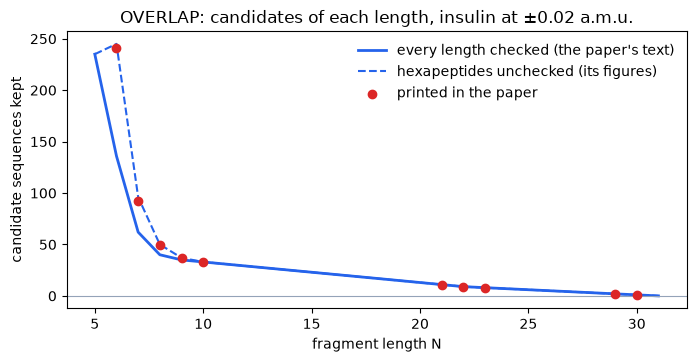

In [18]:
lengths = sorted(sizes)
figure, axes = plt.subplots(figsize=(8, 3.6))
axes.plot(
    lengths,
    [sizes[length] for length in lengths],
    color="#2563eb",
    lw=2,
    label="every length checked (the paper's text)",
)
axes.plot(
    lengths,
    [sizes_as_printed[length] for length in lengths],
    color="#2563eb",
    lw=1.5,
    linestyle="--",
    label="hexapeptides unchecked (its figures)",
)
axes.scatter(
    list(paper_with_fig9),
    list(paper_with_fig9.values()),
    color="#dc2626",
    zorder=3,
    s=36,
    label="printed in the paper",
)
axes.axhline(0, color="#94a3b8", lw=0.8)
axes.set_xlabel("fragment length N")
axes.set_ylabel("candidate sequences kept")
axes.set_title("OVERLAP: candidates of each length, insulin at ±0.02 a.m.u.")
axes.legend(frameon=False)
plt.show()

## The tryptophan error, demonstrated

Run the same lookup with the true tryptophan mass, and W (residue 186.079)
falls within 0.02 of the dipeptide G+E (186.064). Every "EG" in insulin then
also reads as a W.

In [19]:
# Free tryptophan at its true mass, as a residue of the paper's table.
free_tryptophan = MASSES["W"] + H2O
masses_true_w = dict(MASSES_1970, W=free_tryptophan - H2O_1970)
compositions_true_w = masfrg(observed, masses_true_w, H2O_1970, 4)
print(
    "with the printed W:",
    [len(compositions[length]) for length in (1, 2, 3)],
    " (paper: 16, 66, 197)",
)
print(
    "with the true W:   ",
    [len(compositions_true_w[length]) for length in (1, 2, 3)],
)
print(
    "\nanswer with the true W:",
    run(observed, masses_true_w, H2O_1970).chains(25),
)

with the printed W: [16, 66, 197]  (paper: 16, 66, 197)
with the true W:    [17, 71, 208]

answer with the true W: ['AKPTOFFGREGCVJOJAEVJHSGCJHQNVF', 'AKPTOFFGRWCVJOJAEVJHSGCJHQNVF']


## Resolution: ±0.02 against ±0.05

"If the maximum observable mass was limited to 1000 a.m.u., and the maximum
length of peptides to 9 links, the insulin problem could be solved with a
resolution of ±0.02 a.m.u., but could not be solved at ±0.05 a.m.u."

In [20]:
for tolerance in (0.02, 0.05):
    result = run(Observed(masses, tol_da=tolerance), MASSES_1970, H2O_1970)
    chains = result.chains(20)
    print(f"±{tolerance}: {len(chains)} chains of 20 residues or more")
    for chain in chains:
        print("   ", chain)

±0.02: 2 chains of 20 residues or more
    AKPTOFFGREGCVJOJAEVJHSGCJHQNVF
    GJVEQCCASVCSJOQJENOCN
±0.05: 12 chains of 20 residues or more
    AKPTOFFGREGCVJOJAEVJHSGCJHKNVF
    AKPTOFFGREGCVJOJAEVJHSGCJHQNVF
    AQPTOFFGREGCVJOJAEVJHSGCJHKNVF
    AQPTOFFGREGCVJOJAEVJHSGCJHQNVF
    GJVEKCCASVCSJOKJENOCN
    GJVEKCCASVCSJOQJENOCN
    GJVEQCCASVCSJOKJENOCN
    GJVEQCCASVCSJOQJENOCN
    NCONEJKOJSCVSACCKEVW
    NCONEJKOJSCVSACCQEVW
    NCONEJQOJSCVSACCKEVW
    NCONEJQOJSCVSACCQEVW


At ±0.05 glutamine and lysine (0.036 apart) can no longer be told apart, and
every Q/K position of the answer splits in two: four A chains, four B chains,
and some debris. The answer is not unique, so the problem is not solved.

## Practical considerations: noise


"Random noise masses can be tolerated in surprisingly large quantity because
the resulting peptides so seldom seem to overlap by chance ... If there were no
more than about 4000 actually observed masses in this range [100 to 1100],
including all noise, the spectrum would not be too crowded."

In [21]:
for n_noise in (0, 500, 1000, 2000, 4000, 8000):
    noisy = add_noise(masses, n_random=n_noise, lo=100, hi=1100, seed=0)
    result = run(
        Observed(noisy, tol_da=0.02),
        MASSES_1970,
        H2O_1970,
        max_list=300_000,
    )
    chains = result.chains(15)
    both_found = INSULIN_A in chains and (
        INSULIN_B in chains or INSULIN_B[::-1] in chains
    )
    print(
        f"{n_noise:5} noise masses ({len(noisy):5} in all): "
        f"{len(chains)} chains of 15+, both insulin chains found: "
        f"{both_found}"
        + ("" if result.converged else f"  [{result.reason}]")
    )

    0 noise masses (  302 in all): 2 chains of 15+, both insulin chains found: True


  500 noise masses (  802 in all): 2 chains of 15+, both insulin chains found: True


 1000 noise masses ( 1302 in all): 2 chains of 15+, both insulin chains found: True
 2000 noise masses ( 2302 in all): 2 chains of 15+, both insulin chains found: True


 4000 noise masses ( 4302 in all): 2 chains of 15+, both insulin chains found: True


 8000 noise masses ( 8302 in all): 2 chains of 15+, both insulin chains found: True


The reimplementation tolerates even more than the paper expected: both chains
still come back with 8000 random masses, twice the crowding the paper thought
the limit.

## Practical considerations: longer proteins

"We conclude that as an ideal problem, with true masses only, and no noise, a
protein of 100 links could be reconstructed, using the masses of fragments up
to only about 7 or 8 links long, having a maximum molecular mass in the order
of 800 a.m.u." Three random 100-residue proteins, exact masses, every fragment
below the mass limit:

In [22]:
letters = sorted(MASSES_1970)
for seed in (1, 2, 3):
    rng = random.Random(seed)
    protein = "".join(rng.choice(letters) for _ in range(100))
    row = []
    for limit in (700, 800, 1000):
        spectrum = Observed(
            ideal_masses([protein], 60, limit, MASSES_1970, H2O_1970),
            tol_da=0.001,
        )
        result = run(
            spectrum,
            MASSES_1970,
            H2O_1970,
            mass_limit=limit,
            max_list=300_000,
        )
        found = any(
            chain in (protein, protein[::-1])
            for chain in result.chains(100)
        )
        row.append(f"{limit}: {'solved' if found else 'not solved'}")
    print(f"protein {seed}:  " + ",  ".join(row))

protein 1:  700: not solved,  800: solved,  1000: solved


protein 2:  700: not solved,  800: not solved,  1000: solved
protein 3:  700: solved,  800: solved,  1000: solved


The paper's estimate holds: with masses up to about 800-1000 a.m.u. a
100-residue protein comes back from its fragment masses alone, and below that
it may not.

## And today?

The paper ends: "The actual characteristics of a working system will determine
the practicability of the whole scheme." Fifty-five years on, instruments
measure mass to a few ppm, far better than the ±0.01 a.m.u. the paper asked
for. Does the method work on what they produce? The rest of this notebook asks
that with the rest of the package: `simulate.py` makes the mass list of a
present-day experiment, `modern.py` adapts the reconstruction to it, and the
last sections run it on real ones.

### What present-day data looks like

Dayhoff and Eck's data never existed: every fragment up to nine residues,
observed exactly. An LC-MS run of a non-specific digest (pepsin, as in every
HDX-MS experiment) differs in ways that all matter here: cleavage is uneven,
peptides below about 350 Da hardly retain on the column and are not seen, some
detectable fragments are missed anyway, masses come with a few ppm of error,
and noise masses mix in. `simulate()` makes such a mass list for ubiquitin (76
residues), keeping the truth beside it.

823 fragments detected, 1080 masses reported (noise included)
fragments up to 12 residues inside the 350-6000 Da window that were detected: 62%


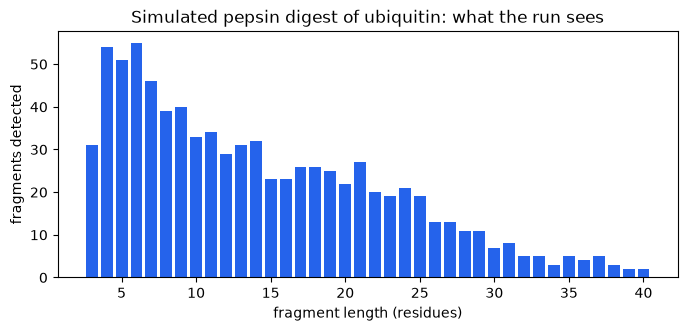

In [23]:
from masspec.evaluate import assemble, score
from masspec.masses import MASSES as PRESENT_DAY
from masspec.modern import FastObserved, run_extend, run_modern
from masspec.simulate import coverage, simulate

UBIQUITIN = (
    "MQIFVKTLTGKTITLEVEPSDTIENVKAKIQDKEGIPPDQQRLIFAGKQLEDGRTLSDYNIQKESTLHLV"
    "LRLRGG"
)
digest = simulate(UBIQUITIN, enzyme="pepsin", ppm=3.0, dropout=0.2,
                  alkylated=False, seed=0)
print(f"{len(digest.peptides)} fragments detected, {len(digest.masses)} "
      f"masses reported (noise included)")
print(f"fragments up to 12 residues inside the 350-6000 Da window that were "
      f"detected: {coverage(digest, 12):.0%}")

by_length = {}
for start, end, _, _ in digest.peptides:
    by_length[end - start + 1] = by_length.get(end - start + 1, 0) + 1
lengths_seen = sorted(by_length)
figure, axes = plt.subplots(figsize=(8, 3.2))
axes.bar(lengths_seen, [by_length[length] for length in lengths_seen],
         color="#2563eb", width=0.8)
axes.set_xlabel("fragment length (residues)")
axes.set_ylabel("fragments detected")
axes.set_title("Simulated pepsin digest of ubiquitin: what the run sees")
plt.show()

Nothing shorter than three residues is seen, and that is where MASSPEC starts:
its first phases (MASFRG, PRUNE, CQ) work on compositions of one to four
residues, and every longer candidate must contain observed shorter ones.

### The 1970 reconstruction on it

`run_modern()` is the 1970 program with the smallest changes that let it run
at all: masses outside the observable window are assumed observed (the paper
already did this above 1000 a.m.u.), masses are matched within a ppm tolerance,
and a candidate needs most, not all, of its sub-fragments observed. OVERLAP
itself is unchanged: a candidate of length N is built only from two surviving
candidates of length N-1.

In [24]:
truth = digest.protein
overlap_result = run_modern(Observed(digest.masses, tol_ppm=9.0), PRESENT_DAY)
overlap_score = score(assemble(overlap_result.contigs), truth)
print(f"residues of ubiquitin recovered: {overlap_score['recall_exact']:.0%}; "
      f"reported residues that are right: "
      f"{overlap_score['precision_exact']:.0%}")

residues of ubiquitin recovered: 17%; reported residues that are right: 7%


Because OVERLAP needs every window of the true sequence to survive on its own,
one missing fragment breaks every chain running through it, and with a fifth of
the fragments missing the chains break every few residues.

### Growing chains one residue at a time

`run_extend()` keeps MASSPEC's seeds but grows each chain one residue at a
time, judging an extension by the fragments that END at the new residue: at
least one, and half of those in the window, must be observed, and each observed
mass may support a chain only once (it is one fragment of the protein). A
missing fragment then weakens a chain instead of cutting it.

In [25]:
extend_result = run_extend(FastObserved(digest.masses, 9.0), PRESENT_DAY)
answer = assemble(extend_result.contigs)
extend_score = score(answer, truth)
with_swaps = extend_score["recall_with_equivalents"]
print(f"residues of ubiquitin recovered: {extend_score['recall_exact']:.0%} "
      f"({with_swaps:.0%} counting mass-identical swaps); reported residues "
      f"that are right: {extend_score['precision_exact']:.0%}\n")
print(f"{'Support':>7}  {'Found':<6}Contig")
for contig, support in answer:
    found = "yes" if contig in truth or contig[::-1] in truth else "no"
    print(f"{support:7}  {found:<6}{contig}")

residues of ubiquitin recovered: 61% (61% counting mass-identical swaps); reported residues that are right: 28%

Support  Found Contig
     91  yes   LFAGKQLEDGRTLSDYNL
     75  yes   DQLKAKVNELTDSPEVE
     51  no    AKEGLPPDQQRLLF
     29  no    AKLGADVSQLEK
     29  no    EAGKLQDEKWLL
     28  no    AAKVQDLESSPE
     28  no    EKGGELAKKVNE
     28  no    KAKLQDVTGGL
     27  no    GEAKVADGLTDS
     27  no    FLGAKQEVEKW
     26  no    AAVKAGEDLKW
     26  no    ERVLEFLLRQQ
     24  no    AGNEPPLGEKD
     24  no    AKGLADADKLW
     24  no    EGLKQDVTQVE
     23  no    EVAKDEQLKGK


The answer is a set of contigs, each read in either direction. Masses alone
cannot order them, cannot tell I from L, and cannot tell Q from GA or N from GG
(identical elemental formulas); "Found" is strict, so a contig with one such
swap shows as "no".

### Where it works

The paper's "practical considerations", redone for present-day data: the same
reconstruction over simulated pepsin digests of ubiquitin, three seeds each,
varying the mass error and the share of detectable fragments missed.
`scripts/study.py` runs the full grid, on myoglobin too, with the enzyme, the
lowest observable mass and the noise as well; its table is
`docs/study_table.md`.

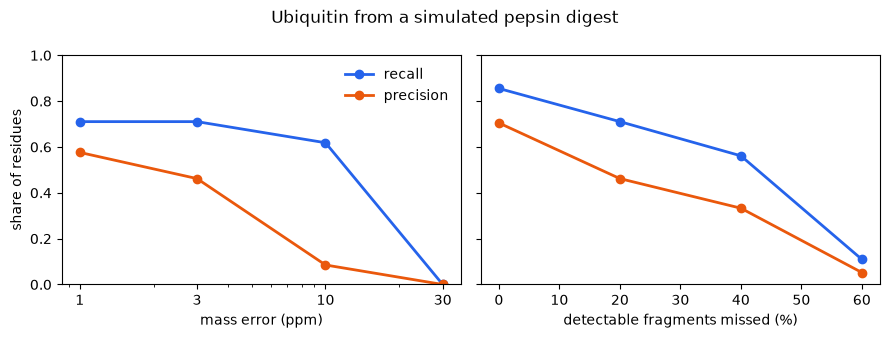

In [26]:
def reconstruct(ppm, dropout):
    # mean recall and precision over three simulated digests
    recalls, precisions = [], []
    for seed in (0, 1, 2):
        simulated = simulate(UBIQUITIN, enzyme="pepsin", ppm=ppm,
                             dropout=dropout, alkylated=False, seed=seed)
        result = run_extend(FastObserved(simulated.masses, 3 * ppm),
                            PRESENT_DAY)
        scored = score(assemble(result.contigs), simulated.protein)
        recalls.append(scored["recall_exact"])
        precisions.append(scored["precision_exact"])
    return sum(recalls) / 3, sum(precisions) / 3


ppm_levels = [1, 3, 10, 30]
dropout_levels = [0.0, 0.2, 0.4, 0.6]
by_ppm = [reconstruct(ppm, 0.2) for ppm in ppm_levels]
by_dropout = [reconstruct(3.0, dropout) for dropout in dropout_levels]

figure, (left, right) = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for axes, levels, results, label in (
    (left, ppm_levels, by_ppm, "mass error (ppm)"),
    (right, [100 * level for level in dropout_levels], by_dropout,
     "detectable fragments missed (%)"),
):
    axes.plot(levels, [recall for recall, _ in results], marker="o",
              color="#2563eb", lw=2, label="recall")
    axes.plot(levels, [precision for _, precision in results], marker="o",
              color="#ea580c", lw=2, label="precision")
    axes.set_xlabel(label)
    axes.set_ylim(0, 1)
left.set_xscale("log")
left.set_xticks(ppm_levels, [str(level) for level in ppm_levels])
left.set_ylabel("share of residues")
left.legend(frameon=False)
figure.suptitle("Ubiquitin from a simulated pepsin digest")
plt.tight_layout()
plt.show()

Mass accuracy decides it, as the paper's arithmetic said it would: at 1-3 ppm,
which any current Orbitrap or FT-ICR gives, most of the protein comes back; at
10 ppm the precision collapses; at 30 ppm nothing does. Completeness is the
other half: the result degrades steadily as fragments go missing, and with
three fifths of them missed little is left.

### A real run

PRIDE project
[PXD071026](https://www.ebi.ac.uk/pride/archive/projects/PXD071026) is an
HDX-MS study of sperm whale myoglobin (154 residues) on an LTQ Orbitrap: one
small protein, pepsin, one run. Its undeuterated run is a present-day version
of the experiment the paper proposed. The data are CC0.

The raw file is 148 MB, so the package carries what the method needs from it:
`masses_from_mzml()` collapsed the run's MS1 scans into one list of 5440
neutral masses (MASSPEC's "single spectrum"), and that list ships as
`masspec.example.pxd071026()`, with the sequences of myoglobin and of pepsin.
`scripts/real_pxd071026.py` starts from the raw file instead, and
`scripts/package_pxd071026.py` rebuilds the packaged list from it.

Two steps remain: `calibrate()` removes the instrument's systematic mass error
using pepsin's own autolysis fragments, which are in every pepsin digest and
never in the protein being sequenced; and the reconstruction runs on the
result.

In [27]:
import bisect

from masspec.example import pxd071026
from masspec.features import calibrate


def fragment_masses(protein, max_len=60):
    # every fragment's mass, with present-day residue masses
    found = set()
    for start in range(len(protein)):
        running = H2O
        for end in range(start, min(len(protein), start + max_len)):
            running += PRESENT_DAY[protein[end]]
            found.add(running)
    return sorted(found)


def matching(masses, protein, ppm=2.0):
    # the masses within `ppm` of some fragment of `protein`
    targets = fragment_masses(protein)
    hits = []
    for value in masses:
        window = value * ppm * 1e-6
        position = bisect.bisect_left(targets, value - window)
        if position < len(targets) and targets[position] <= value + window:
            hits.append(value)
    return hits


measured, myoglobin, pepsin = pxd071026()
offset, _, _ = calibrate(measured, pepsin)
calibrated = [value / (1 + offset * 1e-6) for value in measured]
print(f"{len(measured)} masses; systematic error, from pepsin's "
      f"autolysis fragments: {offset:+.2f} ppm")
from_myoglobin = matching(calibrated, myoglobin)
by_chance = matching([value + 0.3 for value in calibrated], myoglobin)
from_pepsin = matching(calibrated, pepsin)
print(f"masses that are myoglobin fragments (2 ppm): "
      f"{len(from_myoglobin)}, of which about {len(by_chance)} by chance")
print(f"masses that are pepsin fragments: {len(from_pepsin)}")
real = assemble(
    run_extend(FastObserved(calibrated, 3.0), PRESENT_DAY).contigs
)
real_recall = score(real, myoglobin)["recall_exact"]
print(f"\nmyoglobin residues recovered: {real_recall:.0%}")
oracle = assemble(
    run_extend(FastObserved(from_myoglobin, 3.0), PRESENT_DAY).contigs
)
oracle_recall = score(oracle, myoglobin)["recall_exact"]
print(f"the same on the myoglobin masses alone, noise removed: "
      f"{oracle_recall:.0%}")

5440 masses; systematic error, from pepsin's autolysis fragments: -5.06 ppm
masses that are myoglobin fragments (2 ppm): 180, of which about 35 by chance
masses that are pepsin fragments: 408



myoglobin residues recovered: 0%


the same on the myoglobin masses alone, noise removed: 6%


Nothing. Not because of accuracy: after calibration the masses are good to
about a ppm. And not because of noise: with every noise mass removed, the few
percent recovered are what the same contigs also score against a shuffled
myoglobin. The run simply holds too few of the fragments the method needs:
about 145 real myoglobin fragments, mostly long, where the simulated pepsin
digest of the same protein yields about 2000. Dayhoff and Eck's insulin problem
had about six masses per residue; this run has about one. An HDX peptide map is
built for the opposite purpose to MASSPEC's: a modest set of well-separated
peptides that tile the protein once.

So the method would work on present-day instruments, but only on an experiment
designed for it: a near-random, deliberately partial digest, with the short
fragments kept. A standard proteomics or HDX run is not that experiment.

### Partial acid hydrolysis

The digest the paper had in mind was partial acid hydrolysis, not pepsin. Two
public deposits come close to it: horse myoglobin (153 residues) hydrolysed in
hydrochloric acid in a microwave oven (microwave-assisted acid hydrolysis),
then LC-MS/MS on an Orbitrap, both made for *de novo* protein sequencing from
MS/MS.

* [PXD003804][pxd003804] (Savidor et al., *MCP* 2017, [doi][dips]): 6 M HCl
  for 4 min; Q Exactive, MS1 scans from 300 m/z; raw file 0.8 GB.
* [PXD030203][pxd030203] (Mai et al., *Anal. Chem.* 2022, [doi][mucs]):
  microwave HCl, beside proteinase K and papain; Orbitrap Fusion Lumos, MS1
  scans from 350 m/z; raw file 2.1 GB.

The raw files are large, but both deposits include PEAKS's *de novo* reading of
every MS/MS spectrum. The package carries that for one run of each:
every distinct peptide read with an average local confidence of 50% or more,
with its precursor's measured mass (`masspec.example.acid_hydrolysates()`;
`scripts/package_acid_hydrolysis.py` writes it from the deposits).

Here, unlike the pepsin run above, the masses are filtered with the answer in
hand: only the reads that are exact, unmodified stretches of horse myoglobin
are kept. It is the best case these runs can give MASSPEC: every mass a real
fragment, and no noise. Beside them, `simulate()`'s dilute-acid hydrolysate of
the same protein, with the same 350 Da floor and a fifth of the fragments
missed.

[pxd003804]: https://www.ebi.ac.uk/pride/archive/projects/PXD003804
[pxd030203]: https://www.ebi.ac.uk/pride/archive/projects/PXD030203
[dips]: https://doi.org/10.1074/mcp.O116.065417
[mucs]: https://doi.org/10.1021/acs.analchem.1c03718

                        reads  myoglobin  per residue   starts  shortest  < 500 Da
PXD003804                5449        739          4.8      129         3        20
PXD030203               16462       1092          7.1      144         3        25
simulated acid                      2364         15.5                  3       163


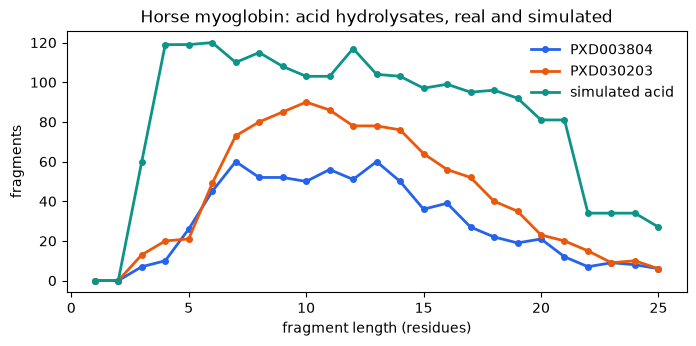

In [28]:
from masspec.example import acid_hydrolysates
from masspec.masses import normalise
from masspec.masses import peptide_mass as modern_mass


def stretches(hydrolysate):
    # each distinct exact, unmodified stretch of myoglobin in the
    # hydrolysate, with the measured mass of the read that found it
    found = {}
    for read in hydrolysate.reads:
        peptide = normalise(read.peptide)
        if "(" not in peptide and peptide in hydrolysate.myoglobin:
            found.setdefault(peptide, read.mass)
    return found


hydrolysates = acid_hydrolysates()
horse = hydrolysates[0].myoglobin
acid_digest = simulate(horse, enzyme="acid", ppm=3.0, dropout=0.2,
                       alkylated=False, seed=0)
simulated_short = sum(1 for _, _, peptide, _ in acid_digest.peptides
                      if modern_mass(peptide) < 500)
print(f"{'':<22}{'reads':>7}{'myoglobin':>11}{'per residue':>13}"
      f"{'starts':>9}{'shortest':>10}{'< 500 Da':>10}")
lengths_by_source = {}
for hydrolysate in hydrolysates:
    found = stretches(hydrolysate)
    starts = {horse.find(peptide) for peptide in found}
    lengths_by_source[hydrolysate.accession] = [
        len(peptide) for peptide in found
    ]
    print(f"{hydrolysate.accession:<22}{len(hydrolysate.reads):>7}"
          f"{len(found):>11}"
          f"{len(found) / len(horse):>13.1f}{len(starts):>9}"
          f"{min(map(len, found)):>10}"
          f"{sum(mass < 500 for mass in found.values()):>10}")
lengths_by_source["simulated acid"] = [
    end - start + 1 for start, end, _, _ in acid_digest.peptides
]
print(f"{'simulated acid':<22}{'':>7}{len(acid_digest.peptides):>11}"
      f"{len(acid_digest.peptides) / len(horse):>13.1f}{'':>9}"
      f"{min(lengths_by_source['simulated acid']):>10}"
      f"{simulated_short:>10}")

figure, axes = plt.subplots(figsize=(8, 3.4))
shown = range(1, 26)
for (source, lengths), color in zip(lengths_by_source.items(),
                                    ("#2563eb", "#ea580c", "#0d9488")):
    axes.plot(shown, [lengths.count(length) for length in shown],
              marker="o", markersize=4, lw=2, color=color, label=source)
axes.set_xlabel("fragment length (residues)")
axes.set_ylabel("fragments")
axes.set_title("Horse myoglobin: acid hydrolysates, real and simulated")
axes.legend(frameon=False)
plt.show()

On the paper's main need, these runs deliver. The HDX run held about one
myoglobin fragment per residue; these hold five to seven, about what
Dayhoff and Eck's insulin problem had (302 masses for 51 residues), and
fragments start at 129 and 144 of the protein's 153 residues. Acid really does
break the chain near-randomly.

The short end is still missing. No fragment shorter than three residues was
read, and only about twenty lighter than 500 Da, where the simulated
hydrolysate, which already loses everything below 350 Da, has 163. Three things
remove them: the MS1 scans start at 300 or 350 m/z; the cleanup (solid-phase
extraction) and the C18 column lose small polar peptides; and the instrument
chooses multiply charged ions for MS/MS, so a singly charged tripeptide is
rarely fragmented and never read. The last point means these lists undercount
what the MS1 scans saw.

What does MASSPEC make of them? First as deposited. Then with the fragments
a run with a low m/z limit would add: every fragment of two to four residues,
with 1.5 ppm of mass error, all of them or with a fifth missed (three draws
each). Those added fragments are made up from the known sequence, so the second
part is a "what if", not a result.

In [29]:
def recover(masses, lo):
    contigs = assemble(
        run_extend(FastObserved(masses, 3.0), PRESENT_DAY, lo=lo).contigs
    )
    scored = score(contigs, horse)
    return scored["recall_exact"], scored["precision_exact"], contigs


def shuffled(protein, seed):
    residues = list(protein)
    random.Random(seed).shuffle(residues)
    return "".join(residues)


short_fragments = sorted({horse[start:start + length]
                          for length in (2, 3, 4)
                          for start in range(len(horse) - length + 1)})
print(f"fragments of 2-4 residues in horse myoglobin: "
      f"{len(short_fragments)}\n")
print(f"{'':<11}{'as deposited':>15}{'+ short, all':>15}"
      f"{'+ short, 20% missed':>22}")
by_chance = {}
for hydrolysate in hydrolysates:
    measured_masses = sorted(stretches(hydrolysate).values())
    recall, precision, contigs = recover(measured_masses, lo=350.0)
    by_chance[hydrolysate.accession] = max(
        score(contigs, shuffled(horse, seed))["recall_exact"]
        for seed in range(10)
    )
    cells = [(recall, precision)]
    for missed in (0.0, 0.2):
        draws = []
        for seed in (0, 1, 2):
            generator = random.Random(seed)
            added = [modern_mass(peptide)
                     * (1 + generator.gauss(0, 1.5e-6))
                     for peptide in short_fragments
                     if generator.random() >= missed]
            draws.append(recover(measured_masses + added, lo=150.0)[:2])
        cells.append(tuple(sum(values) / 3 for values in zip(*draws)))
    widths = (15, 15, 22)
    print(f"{hydrolysate.accession:<11}" + "".join(
        f"{f'{recall:.0%} / {precision:.0%}':>{width}}"
        for (recall, precision), width in zip(cells, widths)))
print("\n(recall / precision: myoglobin residues recovered / reported "
      "residues that are right)")
print("as deposited, the same contigs against ten shuffled myoglobins: "
      + ", ".join(f"{accession} up to {recall:.0%}"
                  for accession, recall in by_chance.items()))

fragments of 2-4 residues in horse myoglobin: 402

              as deposited   + short, all   + short, 20% missed


PXD003804          6% / 6%      41% / 30%             23% / 13%


PXD030203          7% / 6%      51% / 81%             33% / 46%

(recall / precision: myoglobin residues recovered / reported residues that are right)
as deposited, the same contigs against ten shuffled myoglobins: PXD003804 up to 4%, PXD030203 up to 3%


As deposited, little more than chance (6-7% of the protein, against up to 4%
on shuffled myoglobin), even though every mass is a real myoglobin fragment.
With the short fragments added, 41% and 51% of the protein comes back, from
data that are otherwise exactly as deposited. Missing a fifth of those short
fragments costs nearly half of that gain, so a real run would have to see them
reliably.

So the experiment MASSPEC needs is a partial acid hydrolysate like these two,
measured differently: an MS1 range down to about 100 m/z, no cleanup step that
drops small polar peptides (or a column that retains them, such as HILIC),
and singly charged ions kept. No public deposit found so far was measured
that way.

## Fifty-five years on: tandem MS and deep learning

MASSPEC had only intact masses to go on, because in 1970 an instrument could
not pick one peptide out of a mixture and break it apart. Tandem mass
spectrometry does exactly that: it isolates one precursor, fragments it, and
the sequence can be read from that one peptide's fragment ladder, without
reference to any other peptide. Beside its MS1 scans, this run recorded 4505
such MS/MS spectra, with high-resolution HCD fragments.

A present-day *de novo* model reads them directly.
[InstaNovo][instanovo], a transformer, with [InstaNovo+][instanovo-plus]
refining its
less confident calls, was run on them: InstaNovo 1.2.2, the current release,
with the instanovo-v1.2.0 model, on a GPU. A GPU decode does not belong in
this notebook, so its predictions ship with the package
(`masspec.example.pxd071026_instanovo()`);
`scripts/package_instanovo_pxd071026.py` gives the command that made them.

The filter is reference-free, as everything MASSPEC was given: keep a
prediction when its mass is within 10 ppm of the precursor's and InstaNovo's
confidence is at least 0.9. The score is the one used above, against
myoglobin and against shuffled myoglobin.

[instanovo]: https://jeroen.vangoey.be/awesome_de_novo_peptide_sequencing/pages/algorithms/instanovo.html
[instanovo-plus]: https://jeroen.vangoey.be/awesome_de_novo_peptide_sequencing/pages/algorithms/instanovo-plus.html

In [30]:
import re

from masspec.example import pxd071026_instanovo


def plain(peptide):
    # drop the modifications, and write I as L, as everywhere above
    return re.sub(r"\[UNIMOD:\d+\]-?", "", peptide).replace("I", "L")


predictions = pxd071026_instanovo()
confident = sorted({
    plain(row.peptide) for row in predictions
    if abs(row.ppm_error) <= 10 and row.confidence >= 0.9
})
print(f"{len(predictions)} MS/MS spectra read; {len(confident)} distinct "
      f"peptides within 10 ppm at confidence 0.9 or more")

from_myoglobin = [peptide for peptide in confident if peptide in myoglobin]
from_pepsin = [peptide for peptide in confident if peptide in pepsin]
print(f"exact stretches of myoglobin: {len(from_myoglobin)}; of pepsin: "
      f"{len(from_pepsin)}")

contigs = [(peptide, 1.0) for peptide in confident]
instanovo_recall = score(contigs, myoglobin)["recall_exact"]
generator = random.Random(1)
decoy_recalls, decoy_exact = [], []
for _ in range(5):
    residues = list(myoglobin)
    generator.shuffle(residues)
    decoy = "".join(residues)
    decoy_recalls.append(score(contigs, decoy)["recall_exact"])
    decoy_exact.append(sum(peptide in decoy for peptide in confident))
print(f"\nmyoglobin residues recovered: {instanovo_recall:.0%} "
      f"(MASSPEC, from the MS1 masses of the same run: {real_recall:.0%})")
print(f"against five shuffled myoglobins: at most "
      f"{max(decoy_recalls):.0%}, from at most {max(decoy_exact)} exact "
      f"stretches")

covered = set()
for peptide in from_myoglobin:
    start = myoglobin.find(peptide)
    covered.update(range(start, start + len(peptide)))
print("\nmyoglobin, residues covered by InstaNovo's peptides marked ^:")
for start in range(0, len(myoglobin), 60):
    print("  " + myoglobin[start:start + 60])
    print("  " + "".join("^" if position in covered else " "
                         for position in range(start, start + 60)
                         if position < len(myoglobin)))

3843 MS/MS spectra read; 248 distinct peptides within 10 ppm at confidence 0.9 or more
exact stretches of myoglobin: 33; of pepsin: 124



myoglobin residues recovered: 82% (MASSPEC, from the MS1 masses of the same run: 0%)
against five shuffled myoglobins: at most 11%, from at most 0 exact stretches

myoglobin, residues covered by InstaNovo's peptides marked ^:
  VLSEGEWQLVLHVWAKVEADVAGHGQDLLLRLFKSHPETLEKFDRFKHLKTEAEMKASED
  ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  LKKVGVTALTALGALLKKKGHHEAELKPLAQSHATKHKLPLKYLEFLSEALLHVLHSRHP
  ^^^^^^^^^^^^^^^^^^^^^^^^^^                   ^^^^^^^^^^^^^^^
  GDFGADAQGAMNKALELFRKDLAAKYKELGYQGG
  ^^^^^^^^^^^^^^^^^^^^^^^^^^        


Most of myoglobin comes back, as exact peptides, from the very run in which
MASSPEC found nothing beyond chance. Against shuffled myoglobin the same
score stays low, earned by loose alignments rather than exact peptides. Most
of the other confident predictions are pepsin's own peptides,
which are right too, only for the other protein in the tube. What changed is
less the arithmetic than the measurement: a fragment spectrum carries the
sequence ladder of one peptide, where MASSPEC had to infer the order of
residues from which intact fragments happened to overlap.

Between 1970 and now lie more than fifty years of methods: graph and
dynamic-programming algorithms from 1990, probabilistic scoring, hybrids of
sequence tags and database search, and, since 2017, deep learning. The
[Awesome *de novo* peptide sequencing][catalog] catalog maps that whole
history method by method, from Biemann's 1959 paper, the first computer
programs of 1966 and MASSPEC itself to the models of today.

[catalog]: https://jeroen.vangoey.be/awesome_de_novo_peptide_sequencing/